
**IDs**: 342681004, 207884883

**Date**: 08.11.2026

##### Advanced Statistical Analysis and Model-Based Learning (Fall 2026)
# Home Assignment 1
#### Topics:
- The Linear Model
- Linear Least Squares
- Exploratory data analysis
- Normal, Chi-Squared, t, and F distributions

#### Due: November 9 by 18:30

#### Instructions:
- Write your IDs and date at the top cell.
- Submit a copy of this notebook with code filled in the relevant places as the solution of coding exercises.
- For theoretical exercises, you can either write your solution in the notebook using $\LaTeX$ (preffered) or submit additional notes. Your answer to this part will recieve a 5% Bonous if write in $\LaTeX$, up to the maximal assignment grade. 

## Problem 1 (Exploratory Data Analysis)
The Exploratory Data Analysis (EDA) notebook, titled "Assignment 0: Exploratory Data Analysis", has already been released on Moodle.
Complete the EDA assignment according to the instructions provided within that notebook.

Submit your completed EDA notebook, including all required deliverables, together with Homework Assignment 1.

<hr>
<hr>

## Problem 2 (Making a Model)
A social media corporation is experiencing a decline in user engagement over the last few months. One of their team wants to measure the effect of introducing a new feature on the time users interact with their app. The model they want to use has the daily time users spending using their app declining linearly over time, for day $t=0,1,\ldots$. At time $t=35$, they launch the campaign but only for users with a certain test group. They think this could change the slope at time $t=35$ for users within this group (it changes the *slope*, hence would not put a jump discontinuity into the engagement level).

1. Write a linear model that the team can use. Be sure to say what features $\{Z_{ij}\}$ go into the model.
2. Maybe the intervention did not do anything. Which parameter in your model would then be zero? (make sure you have such a parameter in your model).

*The point*: as data scientist/statistician, you have to turn the domain person's intuition into a model. They may not come to you talking about $x$-s and $y$-s and $\beta$ and $\epsilon$. Also, the model might be something they want to disprove.

Answers:

**Note:** In the answers, we assume that both the control and test group have the same slope before the campaign. If not, we can introduce another variable to account for 2 differents slops (thus, another coeficient as well). 

1. Let's define the following variables for our model. 
- $Y_{it}$: interaction time of user i in day t
- $t$: number of days that passed since the observation started
- $G_i$: binary variable indicating if the user i belong to the test group 1 or the control group 0

Let's also define our coeficient:
- $\beta_0$: initial mean time of the control group
- $\beta_1$: initial slope, negative since the interaction time decline over time.
- $\beta_2$: difference in time interaction between the control and test group.
- $\beta_3$: slope change at day 35


Our model: $Y_{it} = \beta_0 + \beta_1t + \beta_2G_i + \beta_3G_i*max(0,t-35) + \epsilon_{it}$

Features: $\{Z_{ij}\} = [1, t, G_i, G_i*max(0,t-35)]$

Explanations:
* We use $max(0,t-35)$ to make sure that the slope change only when we reach the 35th day. 
* The parameter $G_i$ make sure that for the control group we only get the regular slope, since G = 0 for the control group the formula will only be 
$Y_{it} = \beta_0 + \beta_1t + \epsilon_{it}$ which is the slope that decrease over time since users stop using the app as days pass. 
* For the test group (G=1), we have 2 additionals parameters-coeficients. 
    * First we have the $\beta_2G_i$ part. It is here to help us if we want the test and control group to have different engagement. It makes our model more flexible without introducing a jump at day 35. We could remove this part and the model would still work but we preferred to let it here to give the model more flexibility. 
    * The $\beta_3G_i*max(0,t-35)$ is the one really making a difference between the group and the control group. Before day 35, it doesn't change anything which is what we wanted. The intervention changes the test group slope from $\beta_1$ to $\beta_1+\beta_3$ after day 35, without necessarily reversing its direction; the first nonzero adjustment occurs at day 36. 

2. If the intervention has no effect then $\beta_3 = 0$, meaning that the slope of the test group engagement does not change after day 35.

<hr>
<hr>

## Problem 3 (Linearization trick in Sinusoidal Regression)
1. Consider the model:
$$
\mathbb E[Y|X=x] = \beta_0 + \beta_1 \cos\left(2\pi  (x - \beta_2) \right)
$$
with predictor $x$, response variable $y$, and parameters $\beta_0$, $\beta_1$, and $\beta_2$. Is this model linear?

2. Consider instead the model:
$$
\mathbb E[Y|X=x] = \beta_0' + \beta_1' \sin\left(2\pi \cdot x\right) + \beta_2' \cos(2 \pi \cdot x),
$$
with predictor $x$, response variable $y$, and parameters $\beta_0'$, $\beta_1'$, and $\beta_2'$. Is this model linear?

3. Show that the model from 1 can be written as the model in 2 in the sense that $(\beta_0', \beta_1', \beta_2')$ are functions of $(\beta_0, \beta_1, \beta_2)$. Find these functions.

**Answer**: 

1. This model is not linear. For a linear model, we need to be able to write the model as follow $\sum_{i=0}^{n} \beta_{i}f_i(x)$ where the functions f are independents of the parameters. In this case, we have $\beta_2$ appearing inside a non linear function (cosine),violating the independence clause.

2. Yes this model is linear. If we take for formula above, we get $f_0(x) = 1$, $f_1(x) = sin(2\pi x)$ and $f_2(x) = cos(2 \pi x)$ which are independent from the parameters. 

3. We will use the following identity: 
$\cos(A - B) = \cos(A)\cos(B) + \sin(A)\sin(B)$ 

    When we develope $\cos\left(2\pi  (x - \beta_2) \right)$ we get $\cos\left(2\pi(x - \beta_2)\right) = \cos\left(2\pi x - 2\pi\beta_2\right) = \cos(2\pi x)\cos(2\pi\beta_2) + \sin(2\pi x)\sin(2\pi\beta_2)$

    Now our developed formula is $\beta_0 + \beta_1\cos(2\pi x)\cos(2\pi\beta_2) + \beta_1 \sin(2\pi x)\sin(2\pi\beta_2)$. 
    Thus, we only have to define:
    * $\beta_0' = \beta_0 $
    * $\beta_1' = \beta_1 \sin(2\pi\beta_2)$ 
    * $\beta_2' = \beta_1 \cos(2\pi\beta_2)$
<hr>
<hr>


## Problem 4 (Least squares)
For this problem, use the Red Wine Quality Dataset from the UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/186/wine+quality.
Download the file `winequality-red.csv`. Use `quality` as the response variable and all remaining columns as predictors.
1.  Fit a least squares model to `quality` based on the
   other variables and a constant term. Report on the vector of regression coefficients $\hat{\beta}$. Make sure to indicate which entry is associated with each predictor.
3. Plot the response values $y$ and the fitted response $\hat{y} = Z \hat{\beta}$
4. Illustrate the histogram of the residual vector $\hat{\epsilon}$; what is the average of this vector?
5. Write a code that verifies  (using e.g. ``numpy.isclose``):
 - $H = H^\top$
 - $H^2 = H$
 - $\hat{\epsilon}^\top \hat{y} = 0$
 - $\lambda_i(H) \in \{0,1\}$, where $\lambda_i$ is the $i$-th eigenvalue of $H$
 - $\|y\|^2 = \|\hat{\epsilon}\|^2 + \|\hat{y}\|^2$
 - $SS_{total} = SS_{fit} + SS_{residual}$, for the sum of squares decomposition

<hr>
<hr>

### 4.1 — Model, dimensions, and least-squares coefficients

There are $n=1599$ wines and 11 predictors. Including an intercept, the design matrix is
$Z\in\mathbb R^{1599\times12}$, the response is $y\in\mathbb R^{1599}$, and
$\beta\in\mathbb R^{12}$. For wine $i$,
$$y_i=\beta_0+\sum_{j=1}^{11}z_{ij}\beta_j+\epsilon_i.$$
We minimize $\|y-Z\beta\|^2$. When $Z$ has full column rank,
$$\hat\beta=(Z^\top Z)^{-1}Z^\top y.$$
The code uses `np.linalg.lstsq` to solve the least-squares problem without explicitly
forming this inverse; this is numerically more stable.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.precision', 10)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

# The supplied file uses semicolons as delimiters.
data_path = Path('winequality-red.csv')
if not data_path.is_file():
    data_path = Path('Ex1') / 'winequality-red.csv'
data = pd.read_csv(data_path, sep=';')
assert data.shape == (1599, 12)
assert not data.isna().any().any(), 'Handle missing values explicitly before fitting.'
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in data.dtypes)

predictors = data.drop(columns='quality')
y = data['quality'].to_numpy(dtype=float)
Z = np.column_stack([np.ones(len(data)), predictors.to_numpy(dtype=float)])
n, p = Z.shape
names = ['intercept'] + predictors.columns.tolist()

beta_hat, _, rank, singular_values = np.linalg.lstsq(Z, y, rcond=None)
assert rank == p, 'The full-column-rank assumption must hold here.'
y_hat = Z @ beta_hat
residuals = y - y_hat

coefficients = pd.DataFrame({'term': names, 'coefficient': beta_hat})
print(f'n = {n}, p = {p}, rank(Z) = {rank}')
display(coefficients)


n = 1599, p = 12, rank(Z) = 12


,term,coefficient
0,intercept,21.9652084494
1,fixed acidity,0.0249905527
2,volatile acidity,-1.0835902587
3,citric acid,-0.1825639484
4,residual sugar,0.0163312698
5,chlorides,-1.8742251581
6,free sulfur dioxide,0.0043613333
7,total sulfur dioxide,-0.0032645797
8,density,-17.8811638325
9,pH,-0.4136531438


**Interpreting a coefficient.** A coefficient gives the change in the fitted quality score
for a one-unit increase in that predictor, holding the remaining predictors fixed.
This is a conditional model association, not a causal effect. Coefficient magnitudes
cannot be compared directly as measures of importance because the predictors have
different measurement units. The intercept corresponds to all predictors being zero,
which is outside the meaningful range for these wines.

### 4.2 — Observed and fitted response

The left plot shows $y_i$ and $\hat y_i$ at each observation index. The right plot compares
observed and fitted scores directly. Its diagonal represents a perfect fit.
Observation order has no time-series meaning here. Continuous fitted values are expected
even though recorded quality scores are integers.


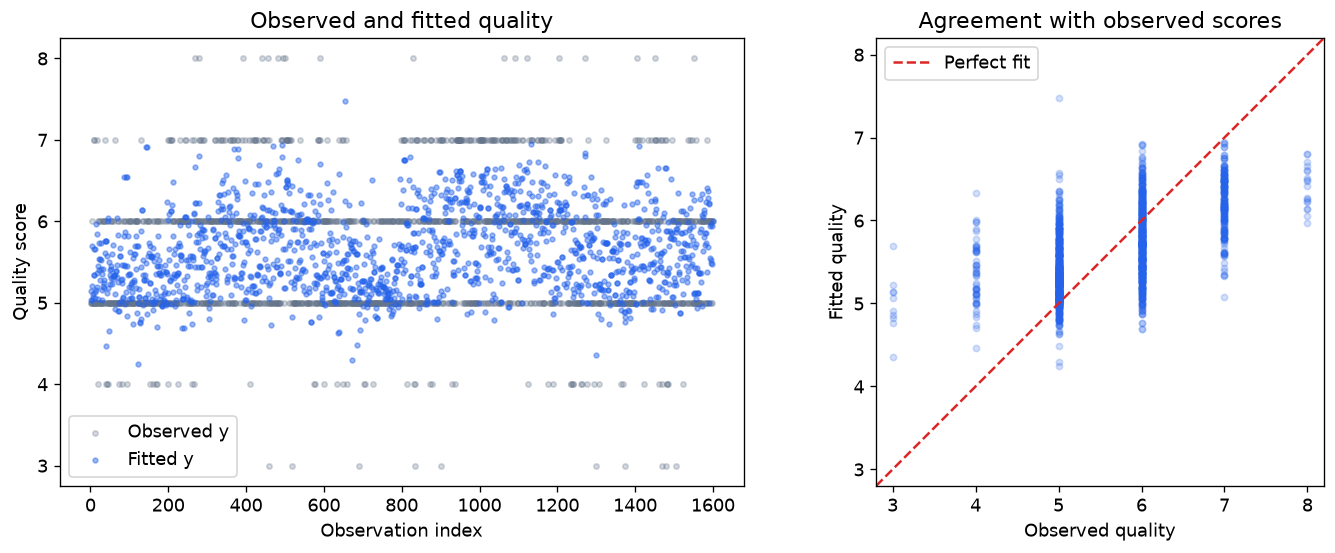

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
index = np.arange(1, n + 1)
axes[0].scatter(index, y, s=10, alpha=0.28, color='#64748b', label='Observed y')
axes[0].scatter(index, y_hat, s=8, alpha=0.45, color='#2563eb', label='Fitted y')
axes[0].set(xlabel='Observation index', ylabel='Quality score', title='Observed and fitted quality')
axes[0].legend()

axes[1].scatter(y, y_hat, s=14, alpha=0.20, color='#2563eb')
low, high = min(y.min(), y_hat.min()) - 0.2, max(y.max(), y_hat.max()) + 0.2
axes[1].plot([low, high], [low, high], '--', color='#dc2626', label='Perfect fit')
axes[1].set(xlabel='Observed quality', ylabel='Fitted quality',
            title='Agreement with observed scores', xlim=(low, high), ylim=(low, high))
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()
plt.show()


### 4.3 — Residual distribution and its mean

A residual is $\hat\epsilon_i=y_i-\hat y_i$: a positive residual means the model
underestimated the recorded quality, and a negative residual means it overestimated it.
The residual mean is theoretically zero because the model includes an intercept:
$$Z^\top\hat\epsilon=0\quad\Longrightarrow\quad
\mathbf1^\top\hat\epsilon=0\quad\Longrightarrow\quad
\overline{\hat\epsilon}=0.$$
In floating-point computation, a tiny nonzero value is expected. A zero mean does not
mean every residual is small, and the histogram alone cannot establish normality.


Mean residual = 1.254536742713e-13
Mean is numerically zero: True


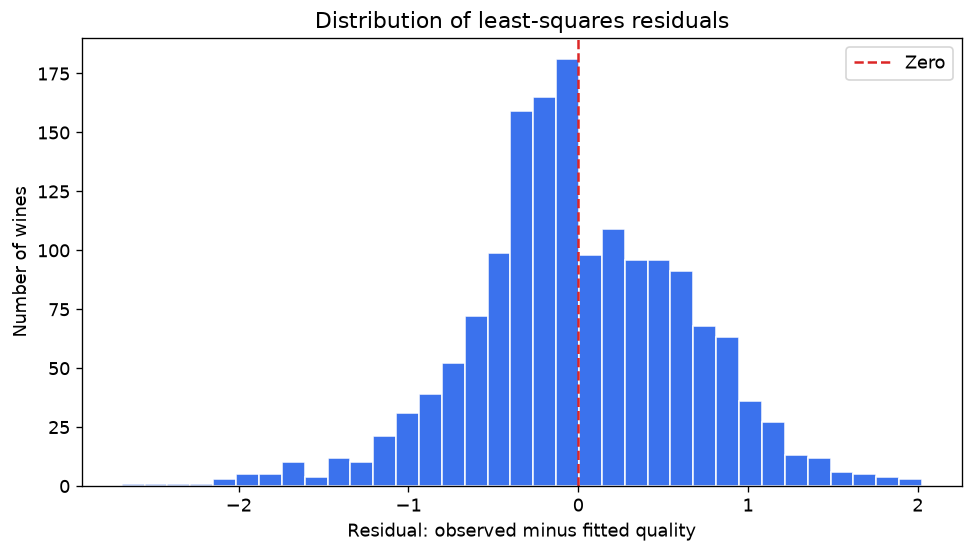

In [3]:
residual_mean = residuals.mean()
print(f'Mean residual = {residual_mean:.12e}')
print('Mean is numerically zero:', np.isclose(residual_mean, 0.0, atol=1e-10))
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(residuals, bins=35, color='#2563eb', edgecolor='white', alpha=0.9)
ax.axvline(0, color='#dc2626', linestyle='--', linewidth=1.5, label='Zero')
ax.set(xlabel='Residual: observed minus fitted quality', ylabel='Number of wines',
       title='Distribution of least-squares residuals')
ax.legend()
plt.show()


### 4.4 — The hat matrix and numerical checks

$$H=Z(Z^\top Z)^{-1}Z^\top,\qquad \hat y=Hy,\qquad
\hat\epsilon=(I-H)y.$$

$H$ is the orthogonal projector onto the column space of $Z$. To construct it stably,
use the reduced QR factorization $Z=QR$, giving $H=QQ^\top$.

- $H=H^\top$: the projection matrix is symmetric.
- $H^2=H$: projecting an already projected vector leaves it unchanged.
- $\hat\epsilon^\top\hat y=0$: the residual is perpendicular to the fit.
- If $Hv=\lambda v$ and $H^2=H$, then $\lambda^2=\lambda$, so each eigenvalue is 0 or 1.
- Since $y=\hat y+\hat\epsilon$ with perpendicular terms,
  $\|y\|^2=\|\hat y\|^2+\|\hat\epsilon\|^2$.
- With an intercept, the centered decomposition also holds:
  $$SS_{total}=\sum_i(y_i-\bar y)^2,\quad
  SS_{fit}=\sum_i(\hat y_i-\bar y)^2,\quad
  SS_{residual}=\sum_i\hat\epsilon_i^2,$$
  $$SS_{total}=SS_{fit}+SS_{residual}.$$
  This follows from $y-\bar y\mathbf1=(\hat y-\bar y\mathbf1)+\hat\epsilon$
  and orthogonality to both $\hat y$ and $\mathbf1$.

The checks use explicit tolerances because floating-point arithmetic is approximate.
`np.allclose` aggregates elementwise approximate comparisons for matrices.


In [4]:
Q, R = np.linalg.qr(Z, mode='reduced')
H = Q @ Q.T
H_squared = H @ H
# eigvalsh is appropriate for this real symmetric matrix.
eigenvalues = np.linalg.eigvalsh(H)

y_bar = y.mean()
ss_total = np.sum((y - y_bar) ** 2)
ss_fit = np.sum((y_hat - y_bar) ** 2)
ss_residual = residuals @ residuals
raw_total = y @ y
raw_components = ss_residual + y_hat @ y_hat
residual_fit_dot = residuals @ y_hat

matrix_atol = 1e-10
scalar_atol = 1e-7
checks = {
    'H = H.T': np.allclose(H, H.T, atol=matrix_atol, rtol=0),
    'H @ H = H': np.allclose(H_squared, H, atol=matrix_atol, rtol=0),
    'residual.T @ fitted = 0': np.isclose(residual_fit_dot, 0, atol=scalar_atol, rtol=0),
    'all eigenvalues are 0 or 1': np.all(
        np.isclose(eigenvalues, 0, atol=matrix_atol, rtol=0) |
        np.isclose(eigenvalues, 1, atol=matrix_atol, rtol=0)),
    '||y||^2 = ||residual||^2 + ||fitted||^2': np.isclose(
        raw_total, raw_components, atol=scalar_atol, rtol=1e-10),
    'SS_total = SS_fit + SS_residual': np.isclose(
        ss_total, ss_fit + ss_residual, atol=scalar_atol, rtol=1e-10),
}
assert np.allclose(H @ y, y_hat, atol=1e-9, rtol=1e-10)
assert all(checks.values()), checks

display(pd.DataFrame({'check': list(checks), 'passed': list(checks.values())}))
diagnostics = pd.Series({
    'max |H - H.T|': np.max(np.abs(H - H.T)),
    'max |H @ H - H|': np.max(np.abs(H_squared - H)),
    'residual.T @ fitted': residual_fit_dot,
    'max distance of eigenvalue from {0, 1}': np.max(
        np.minimum(np.abs(eigenvalues), np.abs(eigenvalues - 1))),
    'number of eigenvalues near 1': np.count_nonzero(np.isclose(eigenvalues, 1, atol=matrix_atol)),
    'number of eigenvalues near 0': np.count_nonzero(np.isclose(eigenvalues, 0, atol=matrix_atol)),
    'raw squared-norm decomposition error': raw_total - raw_components,
    'centered sum-of-squares decomposition error': ss_total - ss_fit - ss_residual,
})
display(diagnostics.to_frame('value'))
display(pd.Series({'SS_total': ss_total, 'SS_fit': ss_fit, 'SS_residual': ss_residual,
                   'R_squared': 1 - ss_residual / ss_total}).to_frame('value'))


,check,passed
0,H = H.T,True
1,H @ H = H,True
2,residual.T @ fitted = 0,True
3,all eigenvalues are 0 or 1,True
4,||y||^2 = ||residual||^2 + ||fitted||^2,True
5,SS_total = SS_fit + SS_residual,True


,value
max |H - H.T|,0.0000000000e+00
max |H @ H - H|,1.7347234760e-16
residual.T @ fitted,1.1102940789e-09
"max distance of eigenvalue from {0, 1}",8.8817841970e-16
number of eigenvalues near 1,1.2000000000e+01
number of eigenvalues near 0,1.5870000000e+03
raw squared-norm decomposition error,2.2191670723e-09
centered sum-of-squares decomposition error,-4.0586201067e-11


,value
SS_total,1042.1651031895
SS_fit,375.7544028025
SS_residual,666.4107003870
R_squared,0.3605517030


## Problem 5 (Weighted least squares)
In some cases we may want to weigh differently the contribution of each coordinate to the loss function. For example, this may be because not all measurements are equally reliable (e.g., new measurements may be more reliable than old ones). One way to account for this difference in reliability is by considering a *weighted* least squares problem, in which we seek $(\beta_1,\ldots,\beta_p) \in \reals^p$ to minimize
$$
S(\beta_1,\ldots,\beta_p) :=
\sum_{i=1}^n w_i^2\left(y_i - \sum_{j=1}^p z_{ij} \beta_j \right)^2 = (W\epsilon )^\top (W\epsilon),
$$
where $W = \mathrm{diag}(w_1,\ldots,w_n)$, $w_i>0$ for all $i=1,\ldots,n$ are the weights associated with the reliability of each coordinate.

1. Write the corresponding Normal Equations in a matrix form
2. Find the optimal vector of weights $\hat{\beta}$ minimizing $S(\beta_1,\ldots,\beta_p)$ in terms of $W$, $Z$, and $y$.
3. What is the hat matrix $H$, i.e. the matrix that satisfies $\hat{y} = H y$ with $\hat{y} = \hat{\beta}Z$? (make sure that your expression reduces to the hat matrix from class when $W$ is the identity matrix)
4. Show that $H^2 = H$ and $(I-H)^2 = I-H$

<hr>
<hr>

### 5 — Weighted least squares: complete derivation

**Notation and assumptions.** Let $Z\in\mathbb R^{n\times p}$ have full column rank,
$y\in\mathbb R^n$, and $\beta\in\mathbb R^p$.
$W=\operatorname{diag}(w_1,\ldots,w_n)$, with $w_i>0$, is given.
Set $A=W^\top W=W^2=\operatorname{diag}(w_i^2)$.
The effective coefficient of the squared residual is $w_i^2$, not $w_i$.
The unknown $\beta$ consists of regression coefficients, not the observation weights.
The assignment's $\hat\beta Z$ is read as $Z\hat\beta$, consistent with these dimensions.

#### 5.1 — Normal equations

Write the objective as
$$S(\beta)=(y-Z\beta)^\top A(y-Z\beta)
=y^\top Ay-2\beta^\top Z^\top Ay+\beta^\top Z^\top AZ\beta.$$
Since $A=A^\top$,
$$\nabla_\beta S=-2Z^\top Ay+2Z^\top AZ\beta.$$
Setting the gradient to zero gives the normal equations:
$$\boxed{Z^\top W^2Z\hat\beta=Z^\top W^2y.}$$

#### 5.2 — Minimizing coefficient vector

For every nonzero $v\in\mathbb R^p$,
$$v^\top Z^\top AZv=\|WZv\|^2>0,$$
because $Z$ has full column rank and $W$ is invertible. Thus $Z^\top AZ$ is positive
definite, the Hessian $2Z^\top AZ$ is positive definite, and the unique minimizer is
$$\boxed{\hat\beta=(Z^\top W^2Z)^{-1}Z^\top W^2y.}$$
If full column rank is not assumed, the coefficient vector need not be unique; one
minimum-norm solution is $(WZ)^+Wy$, where $+$ denotes the Moore–Penrose pseudoinverse.
The following inverse formulas use the full-column-rank assumption.

#### 5.3 — Hat matrix

Substituting the minimizer into $\hat y=Z\hat\beta$ gives
$$\boxed{H=Z(Z^\top W^2Z)^{-1}Z^\top W^2.}$$
When $W=I$, this becomes $Z(Z^\top Z)^{-1}Z^\top$, the ordinary least-squares hat matrix.

#### 5.4 — Idempotence of $H$ and $I-H$

Let $B=Z^\top AZ$. Then
$$\begin{aligned}
H^2
&=ZB^{-1}Z^\top A\,ZB^{-1}Z^\top A\\
&=ZB^{-1}(Z^\top AZ)B^{-1}Z^\top A\\
&=ZB^{-1}BB^{-1}Z^\top A\\
&=ZB^{-1}Z^\top A=H.
\end{aligned}$$
Consequently,
$$\boxed{(I-H)^2=I-2H+H^2=I-H.}$$

**Geometric interpretation.** This $H$ is still a projection, but is generally not
symmetric in the ordinary Euclidean inner product. The normal equations give
$Z^\top A\hat\epsilon=0$, so the residual is orthogonal to the fitted subspace in the
weighted inner product $\langle u,v\rangle_A=u^\top Av$.
Equivalently, this is ordinary least squares on transformed data $Wy$ and $WZ$;
its symmetric projector there is $WZ(Z^\top W^2Z)^{-1}Z^\top W$.


## Problem 6 (Pearson Correlation and $R^2$)

The Pearson correlation of two series of real numbers $x=\{x_i\}_{i=1}^n$ and $y=\{y_i\}_{i=1}^n$ is
$$
\hat{\rho}: = \frac{\sum_{i=1}^n x_i y_i}{\sqrt{\sum_{i=1}^n x_i^2 } \sqrt{\sum_{i=1}^n y_i^2 } } = \frac{x^\top y}{\|x\|\|y\|}
$$
Consider the coefficient of determination $R^2$ from class in regressing $y$ on $x$ (or $x$ on $y$).
1. Show that $\hat{\rho}^2 = R^2$
2. Find conditions on $x$ and $y$ such that $R^2$ is maximal?


### 6 — Pearson correlation and $R^2$

**Notation and conventions.** We keep $\hat\rho$ for the uncentered expression printed
in the question. For regression without an intercept, we use the uncentered coefficient
of determination $R_0^2$. We use $r$ for the usual centered Pearson correlation and
$R^2$ for the usual coefficient of determination in regression with an intercept.
Both cases are addressed within each part below.

#### 6.1 — Squared correlation and the coefficient of determination

**A. The question's uncentered expression: regression without an intercept.**

Assume $x,y\in\mathbb R^n$ are both nonzero. The expression in the question is
$$\hat\rho=\frac{x^\top y}{\|x\|\|y\|}.$$
Fitting $\hat y=\hat b_0x$ by least squares gives
$$\hat b_0=\frac{x^\top y}{x^\top x}.$$
Substituting this coefficient into the residual sum of squares,
$$\begin{aligned}
SS_{residual,0}
&=\|y-\hat b_0x\|^2\\
&=\|y\|^2-2\hat b_0x^\top y+\hat b_0^2\|x\|^2\\
&=\|y\|^2-\frac{(x^\top y)^2}{\|x\|^2}.
\end{aligned}$$
Using the uncentered coefficient of determination for this regression,
$$\boxed{R_0^2:=1-\frac{SS_{residual,0}}{\|y\|^2}
=\frac{(x^\top y)^2}{\|x\|^2\|y\|^2}=\hat\rho^2.}$$
Regressing $x$ on $y$ without an intercept gives the same $R_0^2$, since the final
expression is symmetric in $x$ and $y$.

**B. Usual Pearson correlation: regression with an intercept.**

Assume now that both variables have positive sample variance. Define
$$x_c=x-\bar x\mathbf{1},\qquad y_c=y-\bar y\mathbf{1},$$
$$S_{xx}=x_c^\top x_c>0,\qquad S_{yy}=y_c^\top y_c>0,\qquad S_{xy}=x_c^\top y_c.$$
The usual Pearson correlation is
$$r=\frac{S_{xy}}{\sqrt{S_{xx}S_{yy}}}.$$
For $\hat y=\hat a\mathbf{1}+\hat b_cx$, the normal equations give
$$\hat a=\bar y-\hat b_c\bar x,\qquad \hat b_c=\frac{S_{xy}}{S_{xx}}.$$
Thus $\hat y-\bar y\mathbf{1}=\hat b_cx_c$ and
$$SS_{residual}=\|y_c-\hat b_cx_c\|^2
=S_{yy}-\frac{S_{xy}^2}{S_{xx}}.$$
With the usual centered total sum of squares $SS_{total}=S_{yy}$,
$$\boxed{R^2:=1-\frac{SS_{residual}}{SS_{total}}
=\frac{S_{xy}^2}{S_{xx}S_{yy}}=r^2.}$$
Regressing $x$ on $y$ with an intercept gives the same $R^2$ by symmetry.
If $x$ and $y$ are already centered, then $\hat\rho=r$ and the two calculations coincide.
For general uncentered data, the two correlations and the two definitions of $R^2$
need not agree.

#### 6.2 — Conditions for a maximal coefficient of determination

**A. Without an intercept: maximal $R_0^2$.**

For the nonzero vectors in part 6.1.A, Cauchy–Schwarz gives
$$(x^\top y)^2\leq\|x\|^2\|y\|^2,$$
so $0\leq R_0^2\leq1$. Equality holds exactly when the vectors are linearly dependent:
$$\boxed{R_0^2=1\iff y=bx\text{ for some }b\ne0.}$$
All observations then lie on a straight line through the origin. Positive and negative
values of $b$ both give the maximum; they correspond to $\hat\rho=+1$ and $-1$.

**B. With an intercept: maximal $R^2$.**

Under the positive-variance assumptions in part 6.1.B, apply Cauchy–Schwarz to the
nonzero centered vectors:
$$(x_c^\top y_c)^2\leq\|x_c\|^2\|y_c\|^2.$$
Therefore $0\leq R^2\leq1$, with equality at the maximum exactly when
$$\boxed{R^2=1\iff y_c=bx_c\text{ for some }b\ne0
\iff y_i=a+bx_i\text{ for all }i.}$$
Here $a=\bar y-b\bar x$. The observations lie exactly on a straight line with nonzero
slope; the line may have a nonzero intercept. Both $r=+1$ and $r=-1$ give $R^2=1$.
If either variable is constant, the usual Pearson correlation is undefined; the centered
identity above assumes both variances are positive. In particular, a constant response
makes the usual $R^2$ denominator zero.


<hr>
<hr>